In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import csv


In [11]:
with open("dataset/mnist_train.csv", "r") as file:
    reader = csv.reader(file)
    next(reader)  # Skip header row

    train_data = list(reader)

# Convert training data into numpy array 
train_data = np.array(train_data, dtype=np.float32)

X_train = train_data[:, 1:] / 255.0
Y_train = train_data[:, 0].astype(int)

In [12]:
# One-hot encode target labels
Y_oh = np.zeros((Y_train.shape[0], 10))
Y_oh[np.arange(Y_train.shape[0]), Y_train] = 1

In [13]:
batch_size = 32
epochs = 10
lr = 0.1

In [14]:

m = (X_train.shape[0] // batch_size) * batch_size
X_train = X_train[:m]
Y_train = Y_train[:m]
Y_oh = Y_oh[:m]

# Initialize network weights and biases
np.random.seed(42)
# Layer 1
W1, b1 = np.random.randn(784, 64) * 0.01, np.zeros((1, 64))

# Layer 2
W2, b2 = np.random.randn(64, 10) * 0.01, np.zeros((1, 10))

In [15]:
def relu(x):
    return np.maximum(0, x)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

In [16]:
# Training loop
loss_history = []
accuracy_history = []
for epoch in range(epochs):
  # Shuffle data every epoch
  permutation = np.random.permutation(m)
  X_shuffled = X_train[permutation]
  Y_shuffled = Y_oh[permutation]

  epoch_loss = 0
  num_batches = 0

  # Loop through fixed-size batches
  for i in range(0, m, batch_size):
    X_batch = X_shuffled[i : i + batch_size]
    Y_batch = Y_shuffled[i : i + batch_size]

    # Forward propagation
    Z1 = X_batch.dot(W1) + b1
    A1 = relu(Z1)
    Z2 = A1.dot(W2) + b2
    A2 = softmax(Z2)

    # Calculate batch loss (Cross-Entropy)
    batch_loss = -np.mean(np.sum(Y_batch * np.log(A2 + 1e-8), axis=1))
    epoch_loss += batch_loss
    num_batches += 1

    # Backward propagation (using fixed batch_size directly)
    dZ2 = A2 - Y_batch
    dW2 = A1.T.dot(dZ2) / batch_size
    db2 = np.sum(dZ2, axis=0, keepdims=True) / batch_size
    dZ1 = dZ2.dot(W2.T) * (Z1 > 0)
    dW1 = X_batch.T.dot(dZ1) / batch_size
    db1 = np.sum(dZ1, axis=0, keepdims=True) / batch_size

    # Update weights and biases
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

  # Average loss for the epoch
  avg_epoch_loss = epoch_loss / num_batches
  loss_history.append(avg_epoch_loss)

  # Calculate and save epoch accuracy
  Z1_full = X_train.dot(W1) + b1
  A1_full = relu(Z1_full)
  Z2_full = A1_full.dot(W2) + b2
  preds = np.argmax(softmax(Z2_full), axis=1)
  acc = np.mean(preds == Y_train) * 100
  accuracy_history.append(acc)
  print(
      f"Epoch {epoch+1}/{epochs} - Loss: {avg_epoch_loss:.4f} | Accuracy:"
      f" {acc:.2f}%"
  )

Epoch 1/10 - Loss: 0.4283 | Accuracy: 94.01%
Epoch 2/10 - Loss: 0.1818 | Accuracy: 96.16%
Epoch 3/10 - Loss: 0.1314 | Accuracy: 96.96%
Epoch 4/10 - Loss: 0.1054 | Accuracy: 97.31%
Epoch 5/10 - Loss: 0.0896 | Accuracy: 97.88%
Epoch 6/10 - Loss: 0.0770 | Accuracy: 97.97%
Epoch 7/10 - Loss: 0.0677 | Accuracy: 98.14%
Epoch 8/10 - Loss: 0.0602 | Accuracy: 98.50%
Epoch 9/10 - Loss: 0.0533 | Accuracy: 98.66%
Epoch 10/10 - Loss: 0.0488 | Accuracy: 98.92%


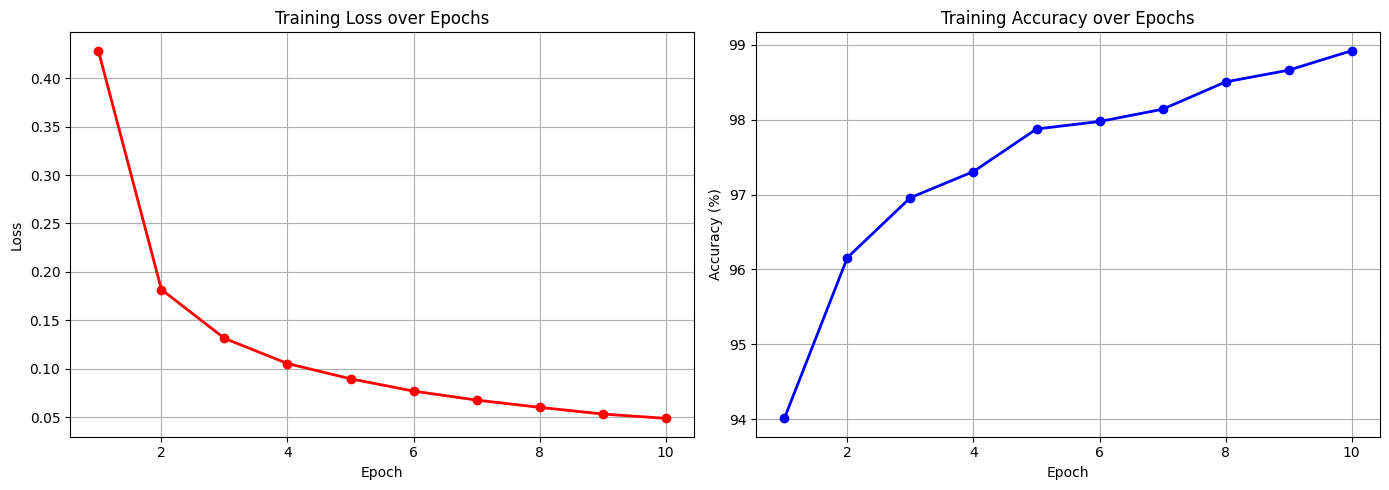

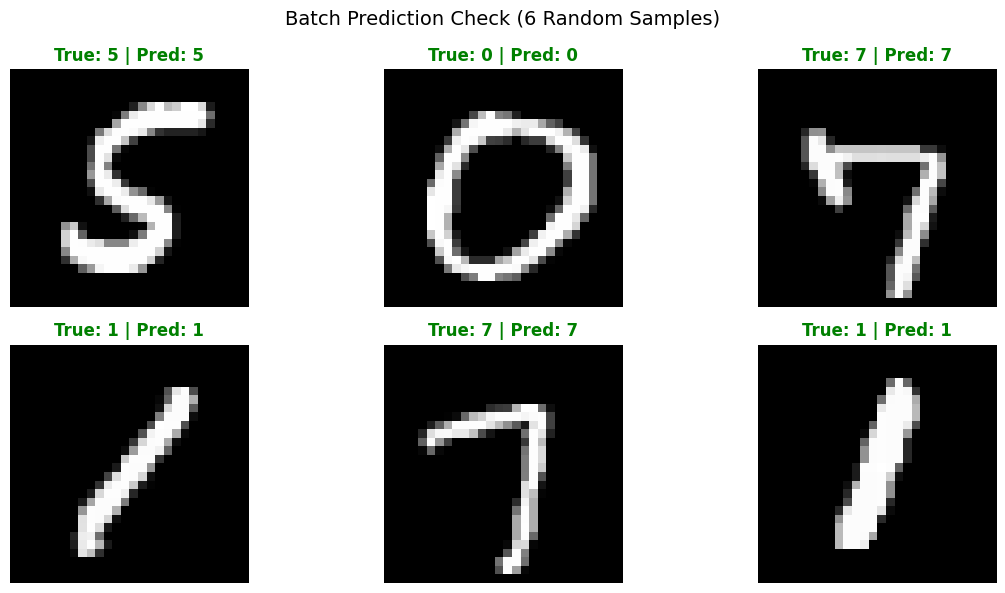

In [ ]:
import csv
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. LOAD AND PREPROCESS TRAINING DATA
# ==========================================
with open("dataset/mnist_train.csv", "r") as file:
  reader = csv.reader(file)
  next(reader)  # Skip header row
  train_data = list(reader)

train_data = np.array(train_data, dtype=np.float32)

X_train = train_data[:, 1:] / 255.0
Y_train = train_data[:, 0].astype(int)

# One-hot encode target labels for training
Y_oh = np.zeros((Y_train.shape[0], 10))
Y_oh[np.arange(Y_train.shape[0]), Y_train] = 1

batch_size = 32
epochs = 10
lr = 0.1

# Trimming dataset to be an exact multiple of batch_size
m = (X_train.shape[0] // batch_size) * batch_size
X_train = X_train[:m]
Y_train = Y_train[:m]
Y_oh = Y_oh[:m]

# ==========================================
# 2. LOAD AND PREPROCESS TESTING DATA
# ==========================================
with open("dataset/mnist_test.csv", "r") as file:
  reader = csv.reader(file)
  next(reader)  # Skip header row
  test_data = list(reader)

test_data = np.array(test_data, dtype=np.float32)

X_test = test_data[:, 1:] / 255.0
Y_test = test_data[:, 0].astype(int)

# ==========================================
# 3. INITIALIZE NETWORK & FUNCTIONS
# ==========================================
np.random.seed(42)
# Layer 1 (784 inputs -> 64 hidden neurons)
W1, b1 = np.random.randn(784, 64) * 0.01, np.zeros((1, 64))

# Layer 2 (64 hidden neurons -> 10 outputs)
W2, b2 = np.random.randn(64, 10) * 0.01, np.zeros((1, 10))


def relu(x):
  return np.maximum(0, x)


def softmax(x):
  exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
  return exp_x / np.sum(exp_x, axis=1, keepdims=True)


# ==========================================
# 4. TRAINING LOOP
# ==========================================
loss_history = []
accuracy_history = []

for epoch in range(epochs):
  permutation = np.random.permutation(m)
  X_shuffled = X_train[permutation]
  Y_shuffled = Y_oh[permutation]

  epoch_loss = 0
  num_batches = 0

  for i in range(0, m, batch_size):
    X_batch = X_shuffled[i : i + batch_size]
    Y_batch = Y_shuffled[i : i + batch_size]

    # Forward propagation
    Z1 = X_batch.dot(W1) + b1
    A1 = relu(Z1)
    Z2 = A1.dot(W2) + b2
    A2 = softmax(Z2)

    # Calculate batch loss (Cross-Entropy)
    batch_loss = -np.mean(np.sum(Y_batch * np.log(A2 + 1e-8), axis=1))
    epoch_loss += batch_loss
    num_batches += 1

    # Backward propagation
    dZ2 = A2 - Y_batch
    dW2 = A1.T.dot(dZ2) / batch_size
    db2 = np.sum(dZ2, axis=0, keepdims=True) / batch_size
    dZ1 = dZ2.dot(W2.T) * (Z1 > 0)
    dW1 = X_batch.T.dot(dZ1) / batch_size
    db1 = np.sum(dZ1, axis=0, keepdims=True) / batch_size

    # Update weights and biases
    W1 -= lr * dW1
    b1 -= lr * db1
    W2 -= lr * dW2
    b2 -= lr * db2

  avg_epoch_loss = epoch_loss / num_batches
  loss_history.append(avg_epoch_loss)

  # Calculate training accuracy
  Z1_full = X_train.dot(W1) + b1
  A1_full = relu(Z1_full)
  Z2_full = A1_full.dot(W2) + b2
  preds = np.argmax(softmax(Z2_full), axis=1)
  acc = np.mean(preds == Y_train) * 100
  accuracy_history.append(acc)

  print(
      f"Epoch {epoch+1}/{epochs} - Loss: {avg_epoch_loss:.4f} | Training"
      f" Accuracy: {acc:.2f}%"
  )

# ==========================================
# 5. EVALUATE ON THE TEST DATASET
# ==========================================
Z1_test = X_test.dot(W1) + b1
A1_test = relu(Z1_test)
Z2_test = A1_test.dot(W2) + b2
test_preds = np.argmax(softmax(Z2_test), axis=1)
test_acc = np.mean(test_preds == Y_test) * 100

print("-" * 50)
print(f"Final Test Accuracy on Unseen Data: {test_acc:.2f}%")
print("-" * 50)

# ==========================================
# 6. PLOT TRAINING CURVES
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    range(1, epochs + 1), loss_history, marker="o", color="r", linewidth=2
)
axes[0].set_title("Training Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(
    range(1, epochs + 1), accuracy_history, marker="o", color="b", linewidth=2
)
axes[1].set_title("Training Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ==========================================
# 7. VISUALIZE 6 RANDOM TEST PREDICTIONS
# ==========================================
indices = np.random.choice(X_test.shape[0], 6, replace=False)
X_sample = X_test[indices]
Y_sample = Y_test[indices]
sample_preds = test_preds[indices]

plt.figure(figsize=(12, 6))
for i in range(6):
  plt.subplot(2, 3, i + 1)
  plt.imshow(X_sample[i].reshape(28, 28), cmap="gray")
  true_val = Y_sample[i]
  pred_val = sample_preds[i]
  color = "green" if true_val == pred_val else "red"
  plt.title(
      f"True: {true_val} | Pred: {pred_val}", color=color, fontweight="bold"
  )
  plt.axis("off")

plt.suptitle(
    "Test Dataset Prediction Check (6 Random Unseen Samples)", fontsize=14
)
plt.tight_layout()
plt.show()